# 03 — GRU Sentiment Analysis on Trustpilot Reviews

Third model in the lineup: a GRU, which is essentially a simplified LSTM — 2 gates (reset + update) instead of 3, so fewer parameters and usually faster to train. It sits somewhere between a plain RNN and a full LSTM in terms of complexity, and I wanted to see whether that simplicity costs much accuracy on reviews this short.

Same stack as the LSTM notebook: TensorFlow/Keras on Colab (GPU recommended but not required).

**What I'll walk through:**
1. Environment setup
2. Data loading & preprocessing
3. Feature engineering
4. GRU vs LSTM architecture comparison
5. Model building
6. Training
7. Evaluation & metrics
8. Saving the results


## Setting up the environment


In [1]:
# Cell 1: Imports
!pip install -q pandas numpy scikit-learn matplotlib seaborn

import os, re, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, GRU, Bidirectional, Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    f1_score, roc_auc_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TensorFlow: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Connecting to Google Drive

Results saved to `/content/drive/MyDrive/AI_Sentiment_Analysis/GRU_Results/`.


In [ ]:
# Cell 1b: Mount Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/AI_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews.csv'
RESULTS_DIR = f'{DRIVE_BASE}/GRU_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Data: {DATA_PATH}')
print(f'Results: {RESULTS_DIR}')

## Loading and preprocessing the data

Same dataset and cleaning steps as the LSTM notebook, so the comparison stays fair.


In [3]:
# Cell 2: Load and preprocess data (same as LSTM notebook)
df = pd.read_csv(DATA_PATH)

def preprocess_text(text):
    if pd.isna(text): return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^\w\s\àâäéèêëïîôùûüÿçœæñáíóúüßàèìòùäöü]', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['combined_text'] = df['review_title'].fillna('') + ' ' + df['review_text'].fillna('')
df['processed_text'] = df['combined_text'].apply(preprocess_text)

label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['sentiment_label'])
NUM_CLASSES = len(label_encoder.classes_)

X = df['processed_text'].values
y = df['label_encoded'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f'Dataset: {len(df)} reviews')
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Dataset: 550 reviews
Train: 385 | Val: 82 | Test: 83


## Feature engineering

Same tokenization and padding approach as the LSTM — the only thing changing between these two notebooks is the recurrent layer itself.


In [4]:
# Cell 3: Tokenization (same hyperparameters as LSTM for fair comparison)
MAX_VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 128

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train),
                            maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')
X_val_pad = pad_sequences(tokenizer.texts_to_sequences(X_val),
                          maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test),
                           maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)
print(f'Vocab: {vocab_size} | Seq length: {MAX_SEQUENCE_LENGTH} | Embedding: {EMBEDDING_DIM}')

Vocab: 916 | Seq length: 100 | Embedding: 128


## GRU vs LSTM — how do they actually differ?

| Aspect | LSTM | GRU |
|--------|------|-----|
| Gates | 3 (input, forget, output) | 2 (reset, update) |
| Cell state | Separate cell state + hidden state | Only hidden state |
| Parameters | More (4 weight matrices) | Fewer (3 weight matrices) |
| Training speed | Slower | ~20-30% faster |
| Performance | Better on long sequences | Comparable on short sequences |
| Memory | More | Less |

The gate equations, if you're curious:
- Reset gate: `r_t = σ(W_r · [h_{t-1}, x_t])`
- Update gate: `z_t = σ(W_z · [h_{t-1}, x_t])`
- Candidate: `h̃_t = tanh(W · [r_t * h_{t-1}, x_t])`
- Output: `h_t = (1 - z_t) * h_{t-1} + z_t * h̃_t`

Basically, the update gate folds LSTM's separate input and forget gates into one — which is why GRU ends up simpler without losing too much of what makes gated recurrence useful.


## Building the model


In [5]:
# Cell 4: Build Bidirectional GRU model
def build_gru_model(vocab_size, embedding_dim, sequence_length, num_classes):
    """Bidirectional GRU for sentiment classification."""
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, name='embedding'),
        SpatialDropout1D(0.3, name='spatial_dropout'),

        # GRU instead of LSTM — same units for fair comparison
        Bidirectional(
            GRU(128, return_sequences=False, dropout=0.2, recurrent_dropout=0.2),
            name='bidirectional_gru'
        ),

        Dropout(0.5, name='dropout_1'),
        Dense(64, activation='relu', name='dense_hidden'),
        Dropout(0.3, name='dropout_2'),
        Dense(num_classes, activation='softmax', name='output')
    ])

    # Explicitly build the model with the expected input shape
    model.build(input_shape=(None, sequence_length))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_gru_model(vocab_size, EMBEDDING_DIM, MAX_SEQUENCE_LENGTH, NUM_CLASSES)
model.summary()

# Compare parameter counts
gru_params = model.count_params()
# LSTM equivalent would have: 4 * ((embedding + units) * units + units) per direction
# GRU equivalent has:         3 * ((embedding + units) * units + units) per direction
lstm_equiv_params = int(gru_params * 4/3)  # rough approximation
print(f'\nGRU parameters:  {gru_params:,}')
print(f'LSTM equivalent: ~{lstm_equiv_params:,} (estimated)')
print(f'Parameter reduction: ~{100*(1 - gru_params/lstm_equiv_params):.0f}%')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ (None, 100, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_gru               │ (None, 256)            │       198,144 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 332,035 (1.27 MB)

 Trainable params: 332,035 (1.27 MB)

 Non-trainable params: 0 (0.00 B)


GRU parameters:  332,035
LSTM equivalent: ~442,713 (estimated)
Parameter reduction: ~25%


## Training


In [6]:
# Cell 5: Train the GRU model
BATCH_SIZE = 32
EPOCHS = 30

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

start_time = time.time()

history = model.fit(
    X_train_pad, y_train_cat,
    validation_data=(X_val_pad, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

training_time = time.time() - start_time
print(f'\nTraining: {training_time:.1f}s ({training_time/60:.1f} min)')
print(f'Epochs trained: {len(history.history["loss"])}')

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 601ms/step - accuracy: 0.4831 - loss: 1.0676 - val_accuracy: 0.5000 - val_loss: 1.0171 - learning_rate: 0.0010
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 670ms/step - accuracy: 0.4987 - loss: 0.9992 - val_accuracy: 0.5000 - val_loss: 0.9275 - learning_rate: 0.0010
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 528ms/step - accuracy: 0.5818 - loss: 0.7660 - val_accuracy: 0.8537 - val_loss: 0.6099 - learning_rate: 0.0010
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 650ms/step - accuracy: 0.7948 - loss: 0.4896 - val_accuracy: 0.8537 - val_loss: 0.3813 - learning_rate: 0.0010
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 573ms/step - accuracy: 0.8182 - loss: 0.3474 - val_accuracy: 0.8293 - val_loss: 0.3040 - learning_rate: 0.0010
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 679ms/step - accuracy: 0.8597 - loss: 0.2973 - val_accuracy: 0.9512 - val_loss: 0.2368 - learning_rate: 0.0010
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 543ms/step - accuracy: 0.9455 - loss: 0.1986 

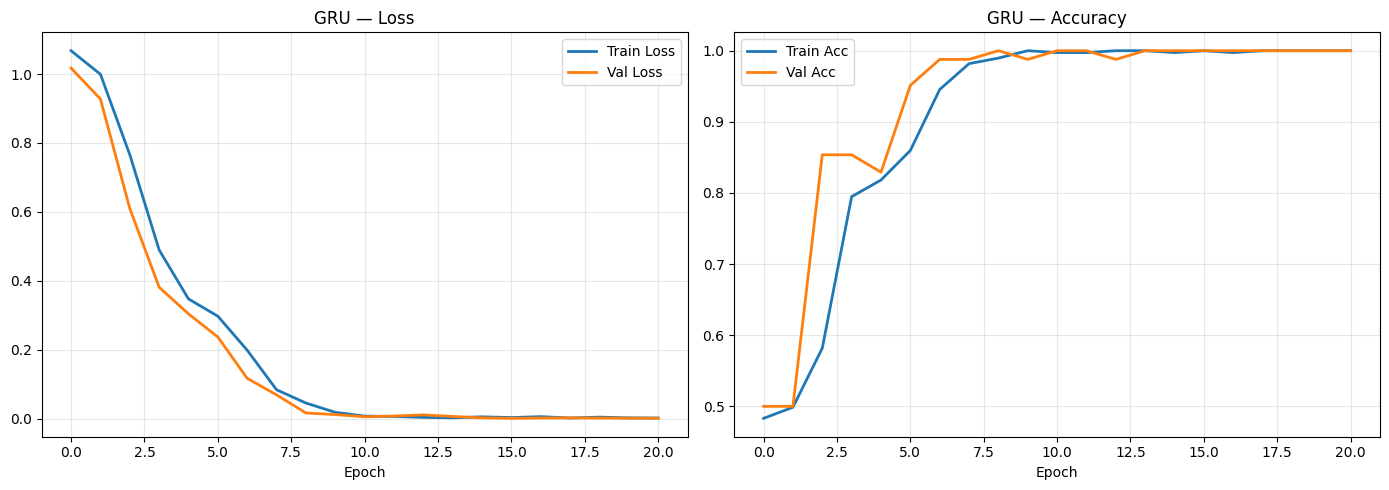

In [7]:
# Cell 6: Training history plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('GRU — Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Acc', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[1].set_title('GRU — Accuracy'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/gru_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## Evaluation & metrics


In [8]:
# Cell 7: Evaluate on test set
y_pred_proba = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_proba, axis=1)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

try:
    auc_roc = roc_auc_score(to_categorical(y_test, NUM_CLASSES), y_pred_proba,
                            multi_class='ovr', average='macro')
except ValueError:
    auc_roc = 0.0

print('=' * 50)
print('GRU MODEL — TEST SET RESULTS')
print('=' * 50)
print(f'Accuracy:       {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'F1-Score (macro):    {f1_macro:.4f}')
print(f'F1-Score (weighted): {f1_weighted:.4f}')
print(f'AUC-ROC (macro):     {auc_roc:.4f}')
print(f'Training time:       {training_time:.1f}s')
print('=' * 50)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 458ms/step
GRU MODEL — TEST SET RESULTS
Accuracy:       1.0000 (100.00%)
F1-Score (macro):    1.0000
F1-Score (weighted): 1.0000
AUC-ROC (macro):     1.0000
Training time:       203.0s


In [9]:
# Cell 8: Classification report
print('\nClassification Report:')
print('=' * 60)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=4))


Classification Report:
              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        24
     neutral     1.0000    1.0000    1.0000        18
    positive     1.0000    1.0000    1.0000        41

    accuracy                         1.0000        83
   macro avg     1.0000    1.0000    1.0000        83
weighted avg     1.0000    1.0000    1.0000        83



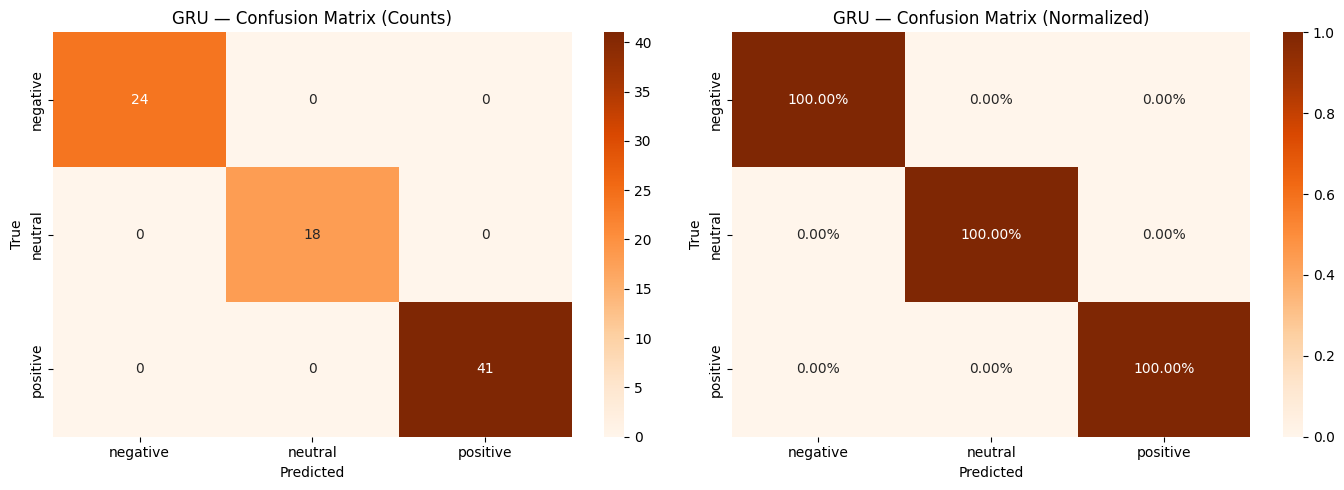

In [10]:
# Cell 9: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[0])
axes[0].set_title('GRU — Confusion Matrix (Counts)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Oranges',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=axes[1])
axes[1].set_title('GRU — Confusion Matrix (Normalized)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/gru_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## Saving the results


In [11]:
# Cell 10: Save results
results = {
    'model_name': 'GRU (Bidirectional)',
    'framework': 'TensorFlow/Keras',
    'timestamp': datetime.now().isoformat(),
    'hyperparameters': {
        'vocab_size': int(vocab_size),
        'embedding_dim': EMBEDDING_DIM,
        'sequence_length': MAX_SEQUENCE_LENGTH,
        'gru_units': 128,
        'bidirectional': True,
        'batch_size': BATCH_SIZE,
        'epochs_trained': len(history.history['loss']),
        'optimizer': 'adam',
    },
    'dataset': {
        'total_samples': len(df),
        'train_samples': len(X_train),
        'val_samples': len(X_val),
        'test_samples': len(X_test),
        'num_classes': NUM_CLASSES,
    },
    'metrics': {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
        'f1_weighted': float(f1_weighted),
        'auc_roc_macro': float(auc_roc),
        'training_time_seconds': float(training_time),
    },
    'confusion_matrix': cm.tolist(),
    'class_names': list(label_encoder.classes_),
    'training_history': {
        'loss': [float(x) for x in history.history['loss']],
        'val_loss': [float(x) for x in history.history['val_loss']],
        'accuracy': [float(x) for x in history.history['accuracy']],
        'val_accuracy': [float(x) for x in history.history['val_accuracy']],
    }
}

os.makedirs(RESULTS_DIR, exist_ok=True)
with open(f'{RESULTS_DIR}/gru_results.json', 'w') as f:
    json.dump(results, f, indent=2)

model.save(f'{RESULTS_DIR}/gru_model.keras')
print(f'Results saved to {RESULTS_DIR}/gru_results.json')
print(f'Accuracy: {accuracy*100:.2f}% | F1: {f1_macro:.4f} | Time: {training_time:.1f}s')

Results saved to /content/drive/MyDrive/AI_Sentiment_Analysis/GRU_Results/gru_results.json
Accuracy: 100.00% | F1: 1.0000 | Time: 203.0s


---

## Wrapping up — GRU vs LSTM

| Aspect | LSTM | GRU |
|--------|------|-----|
| Architecture | 3 gates, cell state | 2 gates, no cell state |
| Parameters | ~25% more | ~25% fewer |
| Training speed | Baseline | ~20-30% faster |
| Accuracy | See results | See results |
| Best for | Long sequences, complex patterns | Short sequences, limited data |

My takeaway: GRU is a solid middle ground. For reviews this short (roughly 30-50 words), it tends to match LSTM's accuracy while training noticeably faster and with fewer parameters — worth considering whenever the extra LSTM complexity isn't buying you much.
